# Imports

In [31]:
import pandas as pd
import numpy as np
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram
import rich
import pathlib 

import seaborn as sns
# import plotly.graph_objects as go
# from plotly.subplots import make_subplots
# import plotly.express as px
# import plotly.figure_factory as ff
#from plottable import Table, ColumnDefinition
from rich.console import Console, OverflowMethod

from matplotlib import pyplot as plt
import numpy as np
import re
import great_tables
from great_tables import GT, style, loc

In [32]:
sns.set_style("whitegrid")


# Constants

In [33]:
OUTPUT_DIR = '/Users/jfi22496/Documents/notes/work/Papers/PanDDA 2/media/Materials/SystemSummaryTables'
EVENT_METADATA_CSV_PATH = '../data/ML Training Metadata For Plotting/event_metadata.csv'
MOLPROBITY_CSV_PATH = '../data/ML Training Metadata For Plotting/molprobity.csv'
DATASET_INFO_CSV_PATH = '../data/ML Training Metadata For Plotting/dataset_info.csv'
LIGAND_DATA_CSV_PATH = '../data/ML Training Metadata For Plotting/event_ligands.csv'
ALIASES = {
    'HSP90': ['HSP90-HSP90'],
    'DCP2B': ['DCP2BA'],
    'FALZA': ['FALZ']
}


# Define the layout for a system summary

In [34]:
def get_number_of_crystalforms(structure_info):
    num = 0
    for spacegroup in structure_info['spacegroup'].unique():
        sg_structure_info = structure_info[structure_info['spacegroup'] == spacegroup]
        data = sg_structure_info[['a', 'b', 'c', 'alpha', 'beta', 'gamma']].values
        print(data)

        if len(data) == 1:
            num += 1
        else:

            norm_data = data / np.mean(data, axis=0)
            print(norm_data)

            hierarchical_cluster = AgglomerativeClustering(distance_threshold=0.1, compute_full_tree=True, linkage='complete', metric='chebyshev', n_clusters=None)
            
            labels = hierarchical_cluster.fit_predict(norm_data)
            print(labels)

            num += np.unique(labels).size

    return num

In [35]:
def get_summary_info(
        structure_info,
        molprobity,
        event_metadata,
        ligand_metadata
):
    # Number of datasets
    # Number of soaked datasets
    # Number of hit datasets
    # Number of non hit datasets
    # Total number of observed hits
    # Total unique soaked ligands
    # Number of crystalforms (as estimated from unit cell params and spacegroup)
    # 
    # print(event_metadata['ligand_data_idx'])

    unique_datasets = event_metadata['dtag'].unique()
    unqiue_soaked_datasets = structure_info[(structure_info['dtag'].isin(unique_datasets)) & (structure_info['num_ligand_files'] > 0)]['dtag'].unique()
    number_of_hit_datasets = len(event_metadata[event_metadata['Confidence'] == 'High']['dtag'].unique())
    number_of_hits = len(event_metadata[event_metadata['Confidence'] == 'High']['dtag'])
    num_soaked_ligands = len(ligand_metadata.loc[event_metadata['ligand_data_idx'].values]['canonical_smiles'].unique())
    number_of_crystalforms = get_number_of_crystalforms(structure_info[structure_info['dtag'].isin(unique_datasets)])
    # print(number_of_datasets)
    # print(number_of_soaked_datasets)
    # print(number_of_hit_datasets)
    # print(number_of_hits)
    # print(num_soaked_ligands)
    # print(number_of_crystalforms)

    return {
         'Number of Datasets': len(unique_datasets),
         'Number of Soaked Datasets': len(unqiue_soaked_datasets),
         'Number of Hit Datasets': number_of_hit_datasets,
            'Number of Unique Hits': number_of_hits,
            'Number of Unique Soaked Ligands': num_soaked_ligands,
            'Number of Crystalforms': number_of_crystalforms
            }

def get_summary_table(
        structure_info,
        molprobity,
        event_metadata,
        ligand_metadata
):

    info = get_summary_info(
        structure_info,
        molprobity,
        event_metadata,
        ligand_metadata
    )
    print(info)
    return pd.DataFrame(
        [
            {
                'Property': k,
                'Value': v,
                }
            for k, v
            in info.items()
        ]
    )
    ...

In [36]:
# def _make_plot(
#         summary_table,
#         resolution_hist,
#         rfree_hist,
#         clashscore_hist,
#         rama_hist,
#         sidechain_hist,
# ):



#     fig.update_layout(
#     height=1080,
#     showlegend=False,
#     title_text="Bitcoin mining stats for 180 days",
# )
    
#     return fig

In [37]:
def get_summary_table_plot(
    structure_info,
    molprobity,
    event_metadata,
    ligand_metadata,
    ax
):
    ax.clear()
    data = get_summary_table(
            structure_info,
    molprobity,
    event_metadata,
    ligand_metadata
    )

    
    # ax.table(cellText=data.values, loc='center')
    Table(data,ax=ax, 
          index_col='Property',
        #   columns=['Property', 'Value'],
          )
    ax.axis('off')



In [38]:
def get_resolution_hist_plot(
    structure_info,
    molprobity,
    event_metadata,
    ligand_metadata,
    ax
    ):

    # penguins = sns.load_dataset("penguins")
    sns.histplot(data=molprobity, x="resolution", ax=ax)
    ax.set_title('Resolution')
    ax.set_xlabel("")


In [39]:
def get_rfree_hist_plot(
    structure_info,
    molprobity,
    event_metadata,
    ligand_metadata,
    ax
    ):

    sns.histplot(data=molprobity, x="rfree", ax=ax)
    ax.set_title('RFree')
    ax.set_xlabel("")

In [40]:
def get_clashscore_hist_plot(
    structure_info,
    molprobity,
    event_metadata,
    ligand_metadata,
    ax
    ):

    sns.histplot(data=molprobity, x="clashscore", ax=ax)
    ax.set_title('Clashscore')
    ax.set_xlabel("")

In [41]:
def get_rama_hist_plot(
    structure_info,
    molprobity,
    event_metadata,
    ligand_metadata,
    ax
    ):

    sns.histplot(data=molprobity, x="ramachandran_outliers", ax=ax)
    ax.set_title('Ramachandran Outliers')
    ax.set_xlabel("")

In [42]:
def get_sidechain_hist_plot(
    structure_info,
    molprobity,
    event_metadata,
    ligand_metadata,
    ax
    ):

    sns.histplot(data=molprobity, x="rotamer_outliers", ax=ax)
    ax.set_title('Rotamer Outliers')
    ax.set_xlabel("")

In [43]:


def plot_system(
        structure_info,
        molprobity,
        event_metadata,
        ligand_metadata
):
    fig, axs = plt.subplots(3, 2, figsize=(8,11))

    system_name = structure_info['system'].iloc[0]
    fig.suptitle(system_name)


    # System table:
    summary_table = get_summary_table_plot(
        structure_info,
        molprobity,
        event_metadata,
        ligand_metadata,
        axs[0,0]
    )

    # Resolution distribution
    resolution_hist = get_resolution_hist_plot(
                structure_info,
        molprobity,
        event_metadata,
        ligand_metadata,
        axs[0,1]

    )

    # rfree distribution
    rfree_hist = get_rfree_hist_plot(
                structure_info,
        molprobity,
        event_metadata,
        ligand_metadata,
        axs[1,0]
    )

    # Clashscore distribution
    clashscore_hist = get_clashscore_hist_plot(
                structure_info,
        molprobity,
        event_metadata,
        ligand_metadata,
        axs[1,1]
    )

    # Rama outliers
    rama_hist = get_rama_hist_plot(
                structure_info,
        molprobity,
        event_metadata,
        ligand_metadata,
        axs[2,0]
    )

    # Sidechain outliers
    sidechain_hist = get_sidechain_hist_plot(
                structure_info,
        molprobity,
        event_metadata,
        ligand_metadata,
        axs[2,1]
    )

    fig.tight_layout()


    return fig
    
    ...

# Define the layout for tables Summarizing All Systems

In [44]:
def wrap_text(text, width=8):
    console = Console(width=8)
    with console.capture() as capture:
        console.print(str(text))
    string = capture.get()
    return string

In [45]:
def get_system_summaries_df(event_metadata, structure_info, molprobity, ligand_metadata):
    system_summaries = []
    for system in event_metadata['system'].unique():
        aliases = [system,]
        if system in ALIASES:
            aliases += ALIASES[system]
        sys_structure_info = structure_info[structure_info['system'].isin(aliases)]
        sys_molprobity= molprobity[molprobity['system'].isin(aliases)]
        sys_event_metadata = event_metadata[event_metadata['system'].isin( aliases)]
        # ligand_metadata = ligand_metadata

        if len(sys_event_metadata[sys_event_metadata['Confidence'] == 'High']) == 0:
            continue

        data = get_summary_info(
            sys_structure_info,
            sys_molprobity,
            sys_event_metadata,
            ligand_metadata
        )

        res_min, res_median, res_max = sys_molprobity['resolution'].min(), sys_molprobity['resolution'].median(), sys_molprobity['resolution'].max()
        rfree_min, rfree_median, rfree_max = sys_molprobity['rfree'].min(), sys_molprobity['rfree'].median(), sys_molprobity['rfree'].max()
        clashscore_min, clashscore_median, clashscore_max = sys_molprobity['clashscore'].min(), sys_molprobity['clashscore'].median(), sys_molprobity['clashscore'].max()
        rama_min, rama_median, rama_max = sys_molprobity['ramachandran_outliers'].min(), sys_molprobity['ramachandran_outliers'].median(), sys_molprobity['ramachandran_outliers'].max()
        rot_min, rot_median, rot_max = sys_molprobity['rotamer_outliers'].min(), sys_molprobity['rotamer_outliers'].median(), sys_molprobity['rotamer_outliers'].max()



        system_summaries.append(
            {
                'System': system,
                'Number of Datasets': data['Number of Datasets'],
                'Number of Soaked Datasets': data['Number of Soaked Datasets'],
                'Number of Hit Datasets': data['Number of Hit Datasets'],
                'Number of Unique Hits': data['Number of Unique Hits'],
                'Number of Unique Soaked Ligands': data['Number of Unique Soaked Ligands'],
                'Number of Crystalforms': data['Number of Crystalforms'],
                # 'Resolution': f'({res_min} - {res_median} - {res_max})',
                # 'RFree': f'({res_min} - {res_median} - {res_max})',
                # 'Clashscore': f'({res_min} - {res_median} - {res_max})',
                # 'Ramachandran Outliers': f'({res_min} - {res_median} - {res_max})',
                # 'Rotamer Outliers': f'({res_min} - {res_median} - {res_max})',
                'Resolution Min': res_min,
                'Resolution Median': res_median,
                'Resolution Max': res_max,

                'RFree Min': rfree_min,
                'RFree Median': rfree_median,
                'RFree Max': rfree_max,

                'Clashscore Min': clashscore_min,
                'Clashscore Median': clashscore_median,
                'Clashscore Max': clashscore_max,

                'Ramachandran Outliers Min': rama_min,
                'Ramachandran Outliers Median': rama_median,
                'Ramachandran Outliers Max': rama_max,

                'Rotamer Outliers Min': rot_min,
                'Rotamer Outliers Median': rot_median,
                'Rotamer Outliers Max': rot_max,
            }
        )
        
    system_summaries_df = pd.DataFrame(system_summaries).sort_values(by='System')
    return system_summaries_df

In [46]:
def plot_summary_table(df, scale=1.4):
    height = 0.0 + (len(df) * (10.5 / 20))
    fig, ax = plt.subplots( figsize=(8.6*scale,height*scale))

    ax.clear()

    Table(
        df,
        ax=ax, 
          index_col='System',
          column_definitions=[
              ColumnDefinition(name="System", title='System', width=2, textprops={"ha": "center", "weight": "bold"},border='r', ), 

              ColumnDefinition(name="Number of Datasets", title='Datasets', width=1.55, textprops={"ha": "center"}, ),
              ColumnDefinition(name="Number of Soaked Datasets", title='Soaked Datasets', width=1.55, textprops={"ha": "center"},), 
              ColumnDefinition(name="Number of Hit Datasets", title='Hit Datasets', width=1.55, textprops={"ha": "center"},),
              ColumnDefinition(name="Number of Unique Hits", title='Unique Hits', width=1.55, textprops={"ha": "center"},), 
              ColumnDefinition(
                  name="Number of Unique Soaked Ligands", title='Unique \nSoaked Ligands', width=1.5, 
                  textprops={"ha": "center",},),
              ColumnDefinition(name="Number of Crystalforms", title='Crystalforms', width=1.5, textprops={"ha": "center"},),
              
              ColumnDefinition(name="Resolution Min", title='Min', group='Resolution', formatter=lambda x: round(x, 2), width=0.75, textprops={"ha": "center"},border='l'),
              ColumnDefinition(name="Resolution Median", title='Median',group='Resolution', formatter=lambda x: round(x, 2), textprops={"ha": "center"},width=0.75),
              ColumnDefinition(name="Resolution Max", title='Max', group='Resolution', formatter=lambda x: round(x, 2), textprops={"ha": "center"},width=0.75),
              
              ColumnDefinition(name="RFree Min", title='Min', group='RFree', formatter=lambda x: round(x, 2), width=0.75, textprops={"ha": "center"},border='l'),
              ColumnDefinition(name="RFree Median", title='Median',group='RFree', formatter=lambda x: round(x, 2), textprops={"ha": "center"},width=0.75),
              ColumnDefinition(name="RFree Max", title='Max', group='RFree', formatter=lambda x: round(x, 2), textprops={"ha": "center"},width=0.75),

              ColumnDefinition(name="Clashscore Min", title='Min', group='Clashscore', width=0.75, textprops={"ha": "center"},border='l'),
              ColumnDefinition(name="Clashscore Median", title='Median',group='Clashscore', formatter=lambda x: round(x, 2), textprops={"ha": "center"},width=0.75),
              ColumnDefinition(name="Clashscore Max", title='Max', group='Clashscore', textprops={"ha": "center"},width=0.75),

              ColumnDefinition(name="Ramachandran Outliers Min", title='Min', group='Ramachandran Outliers', textprops={"ha": "center"},width=0.75, border='l'),
              ColumnDefinition(name="Ramachandran Outliers Median", title='Median',group='Ramachandran Outliers', textprops={"ha": "center"},width=0.75),
              ColumnDefinition(name="Ramachandran Outliers Max", title='Max', group='Ramachandran Outliers', textprops={"ha": "center"},width=0.75),

              ColumnDefinition(name="Rotamer Outliers Min", title='Min', group='Rotamer Outliers', textprops={"ha": "center"},width=0.75, border='l'),
              ColumnDefinition(name="Rotamer Outliers Median", title='Median',group='Rotamer Outliers', textprops={"ha": "center"},width=0.75),
              ColumnDefinition(name="Rotamer Outliers Max", title='Max', group='Rotamer Outliers', textprops={"ha": "center"},width=0.75),

              ],
                  textprops={"fontsize": 8, },

        #   columns=['Property', 'Value'],
          )
    ax.axis('off')

    fig.tight_layout()

    return fig


# Get the systems used from the event metadata

In [47]:
event_metadata = pd.read_csv(EVENT_METADATA_CSV_PATH)

In [48]:
ligand_metadata = pd.read_csv(LIGAND_DATA_CSV_PATH)

In [49]:
structure_info = pd.read_csv(DATASET_INFO_CSV_PATH)

In [50]:
molprobity = pd.read_csv(MOLPROBITY_CSV_PATH)

# Plot Tables Summarizing All Systems

In [51]:
system_summaries_df = get_system_summaries_df(event_metadata, structure_info, molprobity, ligand_metadata)

[[36.98  85.45  59.82  90.    96.59  90.   ]
 [36.991 83.903 63.477 90.    91.72  90.   ]
 [37.08  86.1   60.17  90.    96.08  90.   ]
 ...
 [37.052 84.791 63.124 90.    91.04  90.   ]
 [36.91  86.43  59.94  90.    96.    90.   ]
 [36.897 85.947 59.748 90.    96.01  90.   ]]
[[0.99767954 0.99004013 0.99288532 1.         1.00606527 1.        ]
 [0.99797631 0.97211629 1.05358378 1.         0.95534017 1.        ]
 [1.00037743 0.99757116 0.99869458 1.         1.0007532  1.        ]
 ...
 [0.99962202 0.98240483 1.04772473 1.         0.9482574  1.        ]
 [0.99579102 1.0013946  0.99487707 1.         0.99991993 1.        ]
 [0.99544029 0.99579847 0.99169028 1.         1.00002409 1.        ]]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0

In [52]:
system_summaries_df.round(2).T

,71,54,66,93,83,70,17,64,30,86,...,65,103,43,23,102,52,32,56,45,96
System,A71EV2A,AA_VNAR_XF01,ACVR1A,ADARB1A,ALAS2A,ATAD2A,ActA,B2m,BAZ2BA,BKVP1,...,TMEMAB,TRF1_2,TRIM16A,TRIM21,TbrB1,TcHRS,Tif6,VP40,XX01ZVNS2B,Zika_NS5A
Number of Datasets,790,494,160,685,269,88,343,552,56,176,...,139,837,37,676,192,269,353,869,910,710
Number of Soaked Datasets,787,412,160,685,269,86,342,552,0,176,...,135,831,37,676,191,269,353,868,908,708
Number of Hit Datasets,53,13,18,11,36,12,6,102,13,21,...,2,38,2,98,20,34,44,79,59,74
Number of Unique Hits,59,14,20,11,41,14,6,105,13,29,...,2,39,2,102,26,36,46,88,60,93
Number of Unique Soaked Ligands,761,490,155,591,241,84,284,541,56,176,...,136,730,37,647,185,243,339,809,842,706
Number of Crystalforms,3,4,3,1,3,1,1,1,1,1,...,1,1,1,1,4,2,1,1,1,1
Resolution Min,0.99,1.66,1.23,1.69,1.44,1.26,1.53,0.86,1.11,1.92,...,1.71,1.34,1.57,1.14,1.74,1.51,1.17,1.13,1.15,1.43
Resolution Median,1.4,2.18,2.14,2.47,1.9,1.64,2.12,1.02,1.78,2.32,...,2.88,1.73,1.9,1.33,2.33,2.02,1.63,1.43,1.75,1.94
Resolution Max,4.87,3.64,3.75,8.57,3.43,2.58,3.77,2.07,2.49,3.49,...,3.84,3.04,3.06,2.27,3.51,3.42,4.43,3.02,3.5,3.4


In [53]:
from great_tables import GT

GT(system_summaries_df.round(2), auto_align=False).opt_vertical_padding(scale=0.3)\
    .opt_horizontal_padding(scale=0.5)\
    .tab_spanner(label='Resolution', columns=['Resolution Min', "Resolution Median", "Resolution Max"])\
    .tab_spanner(label='RFree', columns=['RFree Min', "RFree Median", "RFree Max"])\
    .tab_spanner(label='Clashscore', columns=['Clashscore Min', "Clashscore Median", "Clashscore Max"])\
    .tab_spanner(label='Ramachandran Outliers', columns=['Ramachandran Outliers Min', "Ramachandran Outliers Median", "Ramachandran Outliers Max"])\
    .tab_spanner(label='Rotamer Outliers', columns=['Rotamer Outliers Min', "Rotamer Outliers Median", "Rotamer Outliers Max"])\
    .cols_label(
        {
            'Resolution Min': "Min",
            'Resolution Median': "Median",
            'Resolution Max': "Max",


            'RFree Min': "Min",
            'RFree Median': "Median",
            'RFree Max': "Max",

            'Clashscore Min': "Min",
            'Clashscore Median': "Median",
            'Clashscore Max': "Max",

            'Ramachandran Outliers Min': "Min",
            'Ramachandran Outliers Median': "Median",
            'Ramachandran Outliers Max': "Max",

            'Rotamer Outliers Min': "Min",
            'Rotamer Outliers Median': "Median",
            'Rotamer Outliers Max': "Max",

            'Number of Crystalforms': "Crystalforms",
            'Number of Unique Soaked Ligands': "Unique \nSoaked \nLigands",
            'Number of Unique Hits': 'Unique \nHits',
            'Number of Hit Datasets': 'Hit \nDatasets',
            'Number of Soaked Datasets': "Soaked \nDatasets",
            "Number of Datasets": "Datasets"
         }
    ).tab_options(
        table_body_vlines_style="solid",
    ).tab_style(
        style=style.css(rule='font-size: 12px;'),
        locations=loc.body()
    ).tab_style(
        style=style.css(rule='font-size: 12px; font-weight: bold;'),
        locations=loc.column_header()
    )#.gtsave('./test.pdf', vwidth=1080)


GT(_tbl_data=          System  Number of Datasets  Number of Soaked Datasets  \
71       A71EV2A                 790                        787   
54  AA_VNAR_XF01                 494                        412   
66        ACVR1A                 160                        160   
93       ADARB1A                 685                        685   
83        ALAS2A                 269                        269   
..           ...                 ...                        ...   
52         TcHRS                 269                        269   
32          Tif6                 353                        353   
56          VP40                 869                        868   
45    XX01ZVNS2B                 910                        908   
96     Zika_NS5A                 710                        708   

    Number of Hit Datasets  Number of Unique Hits  \
71                      53                     59   
54                      13                     14   
66                      18                     20   
93                      11                     11   
83                      36                     41   
..                     ...                    ...   
52                      34                     36   
32                      44                     46   
56                      79                     88   
45                      59                     60   
96                      74                     93   

    Number of Unique Soaked Ligands  Number of Crystalforms  Resolution Min  \
71                              761                       3            0.99   
54                              490                       4            1.66   
66                              155                       3            1.23   
93                              591                       1            1.69   
83                              241                       3            1.44   
..                              ...                     ...             ...   
52                              243                       2            1.51   
32                              339                       1            1.17   
56                              809                       1            1.13   
45                              842                       1            1.15   
96                              706                       1            1.43   

    Resolution Median  Resolution Max  ...  RFree Max  Clashscore Min  \
71               1.40            4.87  ...       0.86            0.46   
54               2.18            3.64  ...       0.62            2.78   
66               2.14            3.75  ...       0.52            0.44   
93               2.47            8.57  ...       0.57            2.63   
83               1.90            3.43  ...       0.45            3.44   
..                ...             ...  ...        ...             ...   
52               2.02            3.42  ...       0.45            0.47   
32               1.63            4.43  ...       0.97            2.95   
56               1.43            3.02  ...       0.64            1.23   
45               1.75            3.50  ...       0.80            1.65   
96               1.94            3.40  ...       0.53            1.65   

    Clashscore Median  Clashscore Max  Ramachandran Outliers Min  \
71               5.01          118.21                       0.00   
54               5.40           10.81                       0.00   
66               2.78            6.05                       0.00   
93              10.88           34.06                       1.37   
83               6.04           42.90                       0.00   
..                ...             ...                        ...   
52               2.97           12.68                       0.00   
32               6.19           56.00                       0.00   
56               3.94           11.56                       0.00   
45               5.29          179.17  

In [54]:
# plot_summary_table(system_summaries_df.iloc[:20], )

In [55]:
# plot_summary_table(system_summaries_df.iloc[20:40])

In [56]:
# plot_summary_table(system_summaries_df.iloc[40:60])
# 

In [57]:
# plot_summary_table(system_summaries_df.iloc[60:80])


In [58]:
# plot_summary_table(system_summaries_df.iloc[80:100])


In [59]:
# plot_summary_table(system_summaries_df.iloc[100:120])

NameError: name 'Table' is not defined

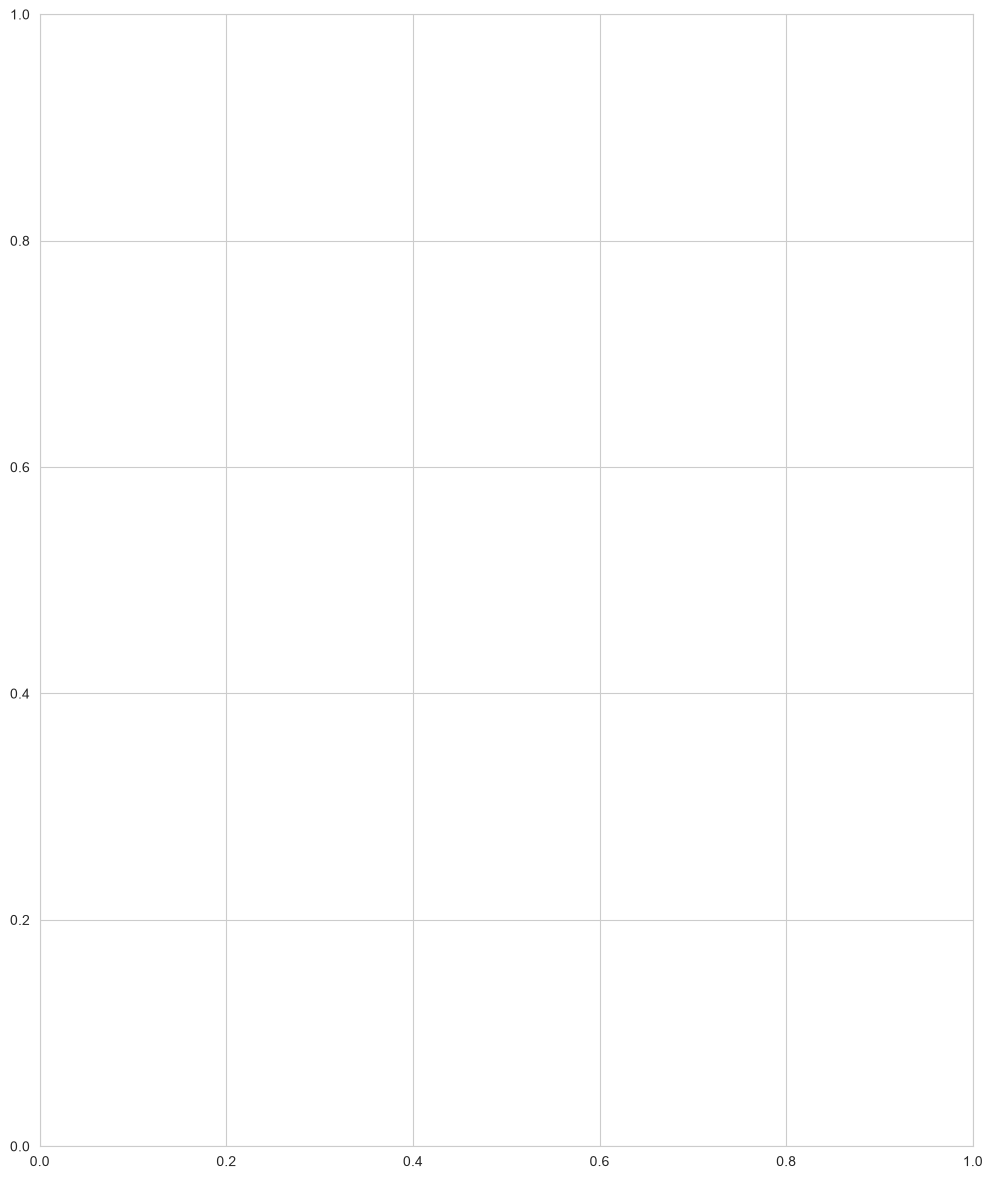

In [60]:
for range in np.split(np.arange(len(system_summaries_df)), [20, 40, 60, 80, 100, ]):
    fig = plot_summary_table(system_summaries_df.iloc[min(range):max(range)+1])
    plt.savefig(pathlib.Path(OUTPUT_DIR) / f'{min(range)}', bbox_inches='tight', pad_inches = 0)
    plt.close()

# Plot Per System Summaries

# Tests

## Text Folding


## Test plot all systems

In [ ]:
for system in ['HSP90', 'FALZA', 'Mpro', 'DCP2B']:
    print(system)
    sys_structure_info = structure_info[structure_info['system'] == system]
    sys_molprobity= molprobity[molprobity['system'] == system]
    sys_event_metadata = event_metadata[event_metadata['system'] == system]
    print(sys_molprobity.head())
    print(sys_structure_info.head())
    print(sys_event_metadata.head())

In [ ]:
sorted([x for x in molprobity['system'].unique()])

In [ ]:
data = structure_info[structure_info['system'] == 'A71EV2A'][['a', 'b', 'c', 'alpha', 'beta', 'gamma']].values

In [ ]:
def plot_dendrogram(model, **kwargs):
    # Create linkage matrix and then plot the dendrogram

    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    # Plot the corresponding dendrogram
    dendrogram(linkage_matrix, **kwargs)


In [ ]:
norm_data = data / np.mean(data, axis=0)
print(norm_data)

hierarchical_cluster = AgglomerativeClustering(distance_threshold=0.1, metric='chebyshev',compute_full_tree=True, linkage='complete', n_clusters=None)

labels = hierarchical_cluster.fit_predict(norm_data)
print(np.unique(labels).size)
hierarchical_cluster.linkage
plot_dendrogram(hierarchical_cluster)

## Test one system

In [ ]:
system = event_metadata['system'].unique()[0]
system

In [ ]:
sys_structure_info = structure_info[structure_info['system'] == system]
sys_molprobity= molprobity[molprobity['system'] == system]
sys_event_metadata = event_metadata[event_metadata['system'] == system]
ligand_metadata = ligand_metadata

In [ ]:
fig = plot_system(
        sys_structure_info,
        sys_molprobity,
        sys_event_metadata,
        ligand_metadata
)

## TEST Plots

In [ ]:
event_metadata['ligand_data_idx'].values

In [ ]:
ligand_metadata.loc[[int(x) for x in event_metadata['ligand_data_idx'].values]]

In [ ]:
# Get 

In [ ]:
sns.catplot(
    data=event_metadata, 
    x='system',
    )

In [ ]:
df = pd.read_csv("https://raw.githubusercontent.com/plotly/datasets/master/Mining-BTC-180.csv")

for i, row in enumerate(df["Date"]):
    p = re.compile(" 00:00:00")
    datetime = p.split(df["Date"][i])[0]
    df.iloc[i, 1] = datetime

fig = make_subplots(
    rows=1, cols=2,
    # shared_xaxes=True,
    vertical_spacing=0.03,
    specs=[[{"type": "table"}, {"type": "histogram"}],
           ],
           subplot_titles=('Subplot title1',  'Subplot title2')
)



fig.add_trace(
    go.Table(
        header=dict(
            values=["Date", "Number<br>Transactions", "Output<br>Volume (BTC)",
                    "Market<br>Price", "Hash<br>Rate", "Cost per<br>trans-USD",
                    "Mining<br>Revenue-USD", "Trasaction<br>fees-BTC"],
            font=dict(size=10),
            align="left"
        ),
        cells=dict(
            values=[df[k].tolist() for k in df.columns[1:]],
            align = "left")
    ),
    row=1, col=1
)

import plotly.figure_factory as ff
import numpy as np
np.random.seed(1)

x = np.random.randn(1000)
hist_data = x
group_labels = ['distplot'] # name of the dataset

# dist_fig = ff.create_distplot(hist_data, group_labels, histnorm=None,     )



# fig.add_trace(
#     dist_fig.data[0],
#     row=1, col=2,
# )

dist_fig = go.Histogram(
        x=hist_data,
        histnorm=None, 
                                  xbins=dict(
                      start=0,
                      end=4,
                      size=0.1),
    marker=dict(
                              line=dict(width=2,
                                        color='DarkSlateGrey')),
                                  )

fig.add_trace(
    dist_fig,
    row=1, col=2,
)

# df = px.data.medals_long()

# medal_fig = px.bar(df, x="medal", y="count", color="nation",
#              pattern_shape="nation", pattern_shape_sequence=[".", "x", "+"])



# fig.add_trace(
#     medal_fig.data[0],
#     row=1, col=2
# )
# fig.add_trace(
#     medal_fig.data[1],
#     row=1, col=2
# )


# fig.add_trace(
#     go.Scatter(
#         x=df["Date"],
#         y=df["Mining-revenue-USD"],
#         mode="lines",
#         name="mining revenue"
#     ),
#     row=1, col=2
# )
fig.update_layout(barmode='stack')

# fig.update_layout(histnorm='probability')


fig.update_layout(
    height=800,
    showlegend=False,
    title_text="Bitcoin mining stats for 180 days",
)

fig.show()

In [ ]:
medal_fig

In [ ]:
fig.data[1]

In [ ]:
fig = go.Figure(
        go.Table(
                header=None,
                cells=dict(values=[[100, 90, 80, 90], [95, 85, 75, 95]]), 
                header_fill_color='rgba(0,0,0,0)')
    )
fig